# Shock sessions of the SN pan GABA PPN mice

This notebook reads one NWB file of the shock session conversion and shows its content: the session and subject
metadata, the fiber photometry signals, the auditory cues, and the dF/F around the cues.

In each session the mouse hears 10 auditory cues of 8 s paired with a shock (CS+) and 10 cues not paired with a shock
(CS-), while GCaMP6f fluorescence of SNr GABA neurons is recorded. The shock times are not in the TDT data, so the
file has the cue times but not the shock times.

The files are not on DANDI. Convert them first:

```bash
shock-sessions convert "<data folder>" "<output folder>"
```

and set `NWBFILE_PATH` below to one of the files.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pynwb import NWBHDF5IO

NWBFILE_PATH = Path("sub-C4551_ses-shocks.nwb")

# Colors of the cue types and plot style
CUE_TYPE_TO_COLOR = {"CS-": "#2a78d6", "CS+": "#eb6834"}
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#52514e",
        "axes.labelcolor": "#0b0b0b",
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "axes.grid": True,
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 1.5,
    }
)

io = NWBHDF5IO(NWBFILE_PATH, "r")
nwbfile = io.read()

## Session and subject

In [2]:
print(f"Session: {nwbfile.session_id}, started {nwbfile.session_start_time}")
print(nwbfile.session_description)
print()
subject = nwbfile.subject
print(f"Subject {subject.subject_id}: {subject.sex}, {subject.genotype} on {subject.strain}, age {subject.age}")

Session: shocks, started 2024-01-23 14:24:44.999999-08:00
The mouse is placed in a shock chamber for 15 minutes and hears 10 auditory cues of 8 s paired with a shock (CS+) and 10 auditory cues of 8 s not paired with a shock (CS-). The shocks were controlled by MedPC and are not recorded in the TDT blocks; the cue intervals table lists the cues.

Subject C4551: M, VGLUT2-Cre x VGAT-Flp on C57BL/6J, age P6W/


## Fiber photometry

The fiber photometry table describes the recording: one row per excitation wavelength, with the location, indicator,
optical fiber, LED and photodetector. Each series points to its row.

In [3]:
fiber_photometry = nwbfile.lab_meta_data["fiber_photometry"]
fiber_photometry.fiber_photometry_table.to_dataframe()[["location", "excitation_wavelength_in_nm", "emission_wavelength_in_nm"]]

,location,excitation_wavelength_in_nm,emission_wavelength_in_nm
id,,,
0,substantia nigra pars reticulata (SNr),465.0,515.0
1,substantia nigra pars reticulata (SNr),405.0,515.0


In [4]:
for name, series in nwbfile.acquisition.items():
    print(f"acquisition/{name}: {series.data.shape[0]} samples, {series.unit}")
for name, series in nwbfile.processing["ophys"].data_interfaces.items():
    print(f"processing/ophys/{name}: {series.data.shape[0]} samples, {series.unit}")

acquisition/raw_signal_SNr: 5503488 samples, a.u.
processing/ophys/deltaF_over_F_SNr: 90169 samples, percent
processing/ophys/demodulated_calcium_signal_SNr: 5503488 samples, a.u.
processing/ophys/demodulated_isosbestic_control_SNr: 5503488 samples, a.u.
processing/ophys/downsampled_calcium_signal_SNr: 90169 samples, a.u.
processing/ophys/downsampled_isosbestic_control_SNr: 90169 samples, a.u.


The processed series were recomputed from the raw signal by `hadjas_2025.processing`, the Python port of the lab's
processing steps; their descriptions say so:

In [5]:
print(nwbfile.processing["ophys"]["deltaF_over_F_SNr"].description)

dF/F of the GCaMP6f signal in the substantia nigra pars reticulata (SNr), in percent, recomputed from the raw signal with hadjas_2025.processing of hnasko-lab-to-nwb 0.0.1, a Python port of the lab's MATLAB code (its bi-exponential fit of the isosbestic signal can differ from the lab's; see the processing module). A biexponential curve was fit to the 100 Hz isosbestic signal and scaled to the 100 Hz 465 nm signal by robust linear regression; dF/F = 100 * (465 nm signal - scaled fit) / scaled fit.


### Raw signal

The raw photodetector signal carries the fluorescence excited by the two LEDs, each modulated at its own frequency.
One tenth of a second shows the modulation.

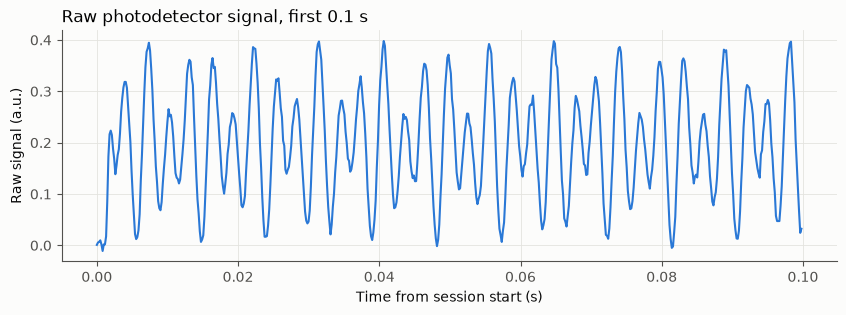

In [6]:
raw_signal = nwbfile.acquisition["raw_signal_SNr"]
raw_times = raw_signal.get_timestamps()
first_samples = slice(0, int(0.1 * len(raw_times) / raw_times[-1]))

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(raw_times[first_samples], raw_signal.data[first_samples], color="#2a78d6")
ax.set_xlabel("Time from session start (s)")
ax.set_ylabel(f"Raw signal ({raw_signal.unit})")
ax.set_title("Raw photodetector signal, first 0.1 s", loc="left")
plt.show()

## Auditory cues

The cue intervals table has one row per cue, from the onset and offset events stored by TDT Synapse.

In [7]:
cues = nwbfile.intervals["auditory_cue_intervals"].to_dataframe()
print(nwbfile.intervals["auditory_cue_intervals"].description)
cues

One row per auditory cue of 8 s, from the cue onset and offset events stored by TDT Synapse. CS+ cues were paired with a shock and CS- cues were not. The shocks were controlled by MedPC and their times are not in the TDT data.


,start_time,stop_time,cue_type,paired_with_shock
id,,,,
0,78.746092,86.744760,CS+,True
1,126.747935,134.746767,CS-,False
2,158.749327,166.747996,CS-,False
3,206.751171,214.749839,CS+,True
4,246.752870,254.751539,CS+,True
5,278.754099,286.753096,CS-,False
6,318.755635,326.754468,CS+,True
7,358.757335,366.756168,CS-,False
8,406.759178,414.758011,CS-,False


## dF/F during the session

dF/F at 100 Hz over the session, with the cues shaded by type. The first second is not shown: it is left out of
the baseline fit, and its dF/F has a large transient.

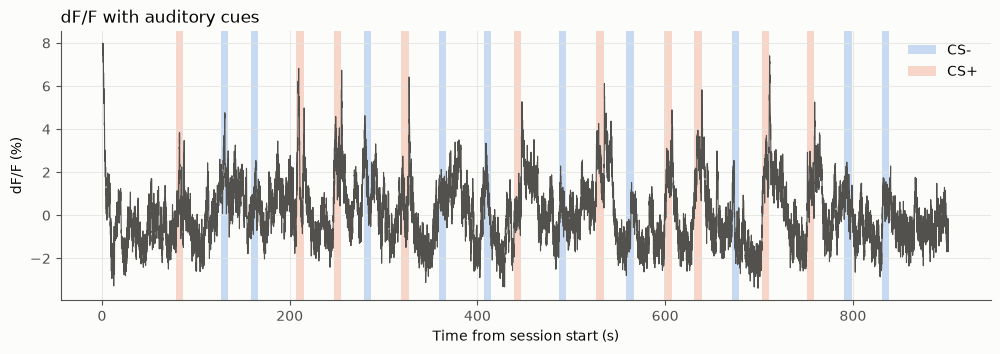

In [8]:
dff = nwbfile.processing["ophys"]["deltaF_over_F_SNr"]
dff_values = dff.data[:]
dff_times = dff.get_timestamps()
after_first_second = dff_times >= 1.0

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(dff_times[after_first_second], dff_values[after_first_second], color="#52514e", linewidth=0.8)
for cue_type, color in CUE_TYPE_TO_COLOR.items():
    for i, cue in enumerate(cues[cues["cue_type"] == cue_type].itertuples()):
        ax.axvspan(cue.start_time, cue.stop_time, color=color, alpha=0.25, linewidth=0, label=cue_type if i == 0 else None)
ax.set_xlabel("Time from session start (s)")
ax.set_ylabel("dF/F (%)")
ax.set_title("dF/F with auditory cues", loc="left")
ax.legend(loc="upper right", frameon=False)
plt.show()

## dF/F around the cues

dF/F from 5 s before to 15 s after each cue onset, averaged over the cues of each type (mean and standard error
across cues). The cue lasts 8 s. When and for how long the shock was delivered within the CS+ cues is not in the
data.

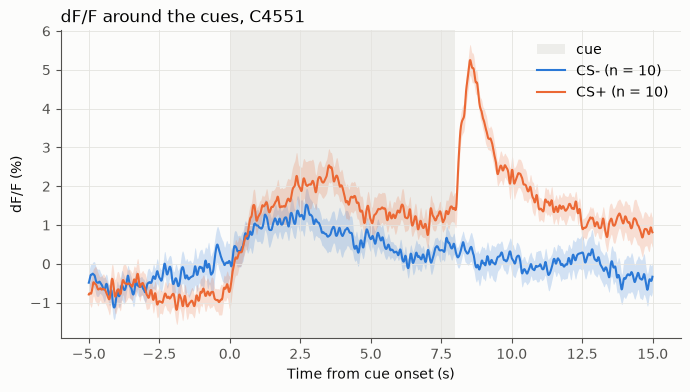

In [9]:
window_in_s = (-5.0, 15.0)
rate = 100.0
relative_times = np.arange(int(window_in_s[0] * rate), int(window_in_s[1] * rate)) / rate

fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(0, 8, color="#e4e3df", alpha=0.6, linewidth=0, label="cue")
for cue_type, color in CUE_TYPE_TO_COLOR.items():
    onsets = cues.loc[cues["cue_type"] == cue_type, "start_time"].to_numpy()
    aligned = np.array([np.interp(onset + relative_times, dff_times, dff_values) for onset in onsets])
    mean = aligned.mean(axis=0)
    sem = aligned.std(axis=0, ddof=1) / np.sqrt(len(onsets))
    ax.fill_between(relative_times, mean - sem, mean + sem, color=color, alpha=0.2, linewidth=0)
    ax.plot(relative_times, mean, color=color, label=f"{cue_type} (n = {len(onsets)})")
ax.set_xlabel("Time from cue onset (s)")
ax.set_ylabel("dF/F (%)")
ax.set_title(f"dF/F around the cues, {nwbfile.subject.subject_id}", loc="left")
ax.legend(loc="upper right", frameon=False)
plt.show()

In [10]:
io.close()